# PM2.5 / PM10 Forecasting — Data Preparation and EDA

This notebook loads hourly observations from 21 stations, reports data-quality issues, performs conservative cleaning, and explores pollutant/weather relationships. No scaling, splitting, or models are fit here. Original CSVs are read-only; a single cleaned CSV is written to a separate `cleaned` subfolder.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from io import BytesIO
import zipfile

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

DATA_DIR = Path(r"C:\Users\jains\Downloads\Air quality dataset")
EXPECTED_STATIONS = 21
EXPECTED_ROWS_PER_STATION = 14_100
EXPECTED_START = pd.Timestamp("2024-05-02 20:00:00")
EXPECTED_END = pd.Timestamp("2025-12-11 07:00:00")
print(f"Data folder: {DATA_DIR}")
print(f"Folder exists: {DATA_DIR.is_dir()}")

Matplotlib is building the font cache; this may take a moment.


Data folder: C:\Users\jains\Downloads\Air quality dataset
Folder exists: True


## 2. Load station CSVs and verify expected coverage

In [3]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Dataset folder is unavailable: {DATA_DIR}")
station_frames = {}
csv_paths = sorted(DATA_DIR.glob("*.csv"))
if csv_paths:
    for csv_path in csv_paths:
        station_id = csv_path.stem
        station_df = pd.read_csv(csv_path, encoding="utf-8", parse_dates=["datetime"])
        station_df["station"] = station_id
        station_frames[station_id] = station_df
else:
    # The provided download may arrive as a ZIP; read CSV members in-place without extracting files.
    archive_paths = sorted(DATA_DIR.rglob("*.zip"))
    if len(archive_paths) != 1:
        raise FileNotFoundError(f"Expected CSV files or one dataset ZIP under {DATA_DIR}; found {len(archive_paths)} ZIP files")
    with zipfile.ZipFile(archive_paths[0]) as archive:
        csv_members = sorted(name for name in archive.namelist() if name.lower().endswith(".csv"))
        if not csv_members:
            raise FileNotFoundError(f"No CSV members found in {archive_paths[0]}")
        for member in csv_members:
            station_id = Path(member).stem
            station_df = pd.read_csv(BytesIO(archive.read(member)), encoding="utf-8", parse_dates=["datetime"])
            station_df["station"] = station_id
            station_frames[station_id] = station_df

df = pd.concat(station_frames.values(), ignore_index=True).sort_values(
    ["station", "datetime"], kind="stable"
).reset_index(drop=True)

print(f"Files/stations found: {len(station_frames)} (expected {EXPECTED_STATIONS})")
print(f"Combined shape: {df.shape}; expected rows: {EXPECTED_STATIONS * EXPECTED_ROWS_PER_STATION:,}")
print("\nDtypes:\n", df.dtypes)
print("\nHead:\n", df.head())

coverage = df.groupby("station")["datetime"].agg(rows="size", start="min", end="max")
coverage["expected_rows"] = EXPECTED_ROWS_PER_STATION
coverage["row_count_ok"] = coverage["rows"].eq(EXPECTED_ROWS_PER_STATION)
coverage["date_range_ok"] = coverage["start"].eq(EXPECTED_START) & coverage["end"].eq(EXPECTED_END)
display(coverage)
print(f"Total row count matches expectation: {len(df) == EXPECTED_STATIONS * EXPECTED_ROWS_PER_STATION}")

Files/stations found: 21 (expected 21)
Combined shape: (296100, 11); expected rows: 296,100

Dtypes:
 datetime          datetime64[us]
PM10                     float64
PM2.5                    float64
temperature              float64
rain                     float64
pressure                 float64
precipitation            float64
wind_speed               float64
clouds                       str
wind_direction               str
station                      str
dtype: object

Head:
              datetime  PM10  PM2.5  temperature  rain  pressure  precipitation  wind_speed            clouds wind_direction station
0 2024-05-02 20:00:00   3.0    2.0         11.0   0.0    1008.0           87.0         3.0  pretežno oblačno            NaN    E403
1 2024-05-02 21:00:00   6.0    3.0         11.0   0.0    1008.0           87.0         3.0     delno oblačno            NaN    E403
2 2024-05-02 22:00:00   7.0    3.0         11.0   0.4    1009.0           84.0        13.0     delno oblačno         

,rows,start,end,expected_rows,row_count_ok,date_range_ok
station,,,,,,
E403,14100,2024-05-02 20:00:00,2025-12-11 07:00:00,14100,True,True
E404,14100,2024-05-02 20:00:00,2025-12-11 07:00:00,14100,True,True
E405,14100,2024-05-02 20:00:00,2025-12-11 07:00:00,14100,True,True
E407,14100,2024-05-02 20:00:00,2025-12-11 07:00:00,14100,True,True
E408,14100,2024-05-02 20:00:00,2025-12-11 07:00:00,14100,True,True
E409,14100,2024-05-02 20:00:00,2025-12-11 07:00:00,14100,True,True
E410,14100,2024-05-02 20:00:00,2025-12-11 07:00:00,14100,True,True
E411,14100,2024-05-02 20:00:00,2025-12-11 07:00:00,14100,True,True
E412,14100,2024-05-02 20:00:00,2025-12-11 07:00:00,14100,True,True


Total row count matches expectation: True


## 3. Duplicate timestamps, hourly gaps, and missingness

Rows participating in duplicate station/timestamp keys: 0


,duplicate_rows,duplicate_timestamps
station,,


Missing timestamps in each station's observed min-to-max hourly index:


,missing_hours,gap_intervals
station,,
E403,0,0
E404,0,0
E405,0,0
E407,0,0
E408,0,0
E409,0,0
E410,0,0
E411,0,0
E412,0,0


Missingness by column:


,missing_count,missing_percent
wind_direction,145598,49.171901
PM10,4902,1.655522
PM2.5,4879,1.647754
pressure,4866,1.643364
precipitation,4551,1.536981
rain,4551,1.536981
temperature,4551,1.536981
clouds,4551,1.536981
wind_speed,4551,1.536981
datetime,0,0.000000


Missing values by station and column:


station,E403,E404,E405,E407,E408,E409,E410,E411,E412,E413,E414,E415,E417,E418,E420,E421,E423,E801,E802,E803,E804
datetime,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
PM10,70,48,368,407,179,94,390,41,43,56,85,141,530,43,44,40,161,34,120,1542,466
PM2.5,70,47,368,407,179,92,390,41,43,56,83,140,530,43,40,40,161,34,120,1542,453
temperature,215,215,215,215,215,215,215,215,215,215,215,215,215,215,215,233,215,215,215,233,215
rain,215,215,215,215,215,215,215,215,215,215,215,215,215,215,215,233,215,215,215,233,215
pressure,230,230,230,230,230,230,230,230,230,230,230,230,230,230,230,248,230,230,230,248,230
precipitation,215,215,215,215,215,215,215,215,215,215,215,215,215,215,215,233,215,215,215,233,215
wind_speed,215,215,215,215,215,215,215,215,215,215,215,215,215,215,215,233,215,215,215,233,215
clouds,215,215,215,215,215,215,215,215,215,215,215,215,215,215,215,233,215,215,215,233,215
wind_direction,6936,6936,6936,6932,6932,6936,6936,6926,6926,6932,6939,6930,6925,6922,6930,6944,6922,6936,6932,6953,6937


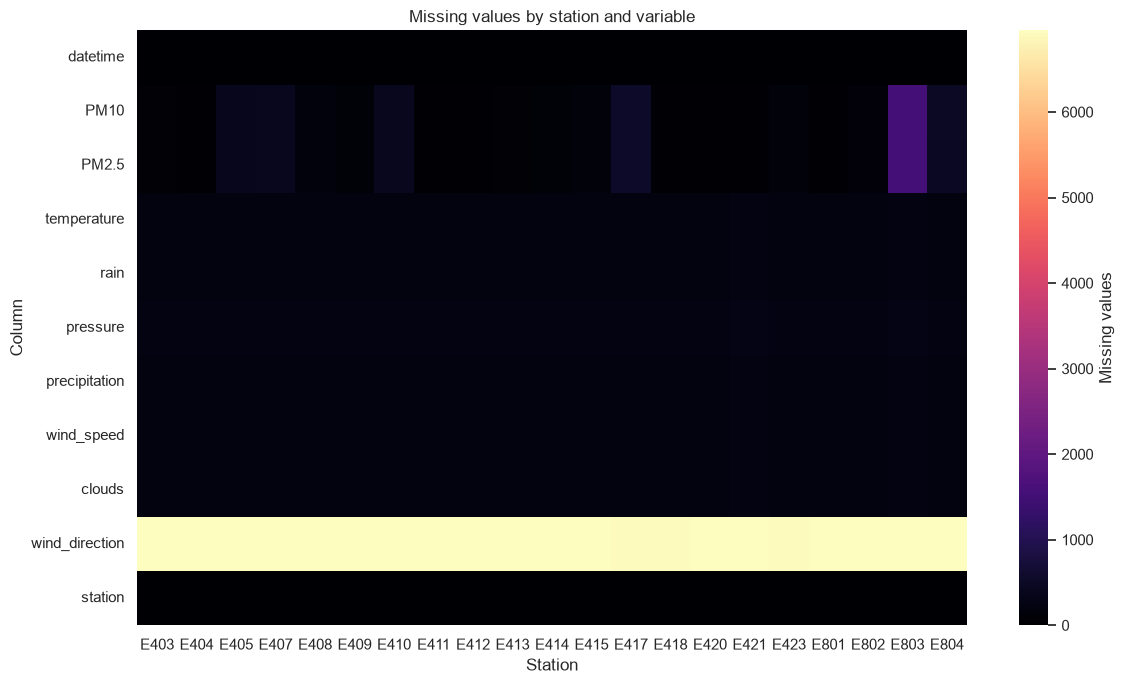

Takeaway: use the table and heatmap to identify station-specific coverage gaps; missing observations are not imputed at this stage.


In [4]:
duplicate_rows = df.duplicated(["station", "datetime"], keep=False)
duplicate_report = (
    df.loc[duplicate_rows].groupby("station")["datetime"].agg(duplicate_rows="size", duplicate_timestamps="nunique")
)
print(f"Rows participating in duplicate station/timestamp keys: {duplicate_rows.sum()}")
display(duplicate_report)

gap_records = []
for station_id, group in df.groupby("station", sort=True):
    times = pd.DatetimeIndex(group["datetime"].dropna().sort_values().unique())
    if len(times) == 0:
        gap_records.append({"station": station_id, "missing_hours": np.nan, "gap_intervals": 0})
        continue
    complete = pd.date_range(times.min(), times.max(), freq="h")
    missing_times = complete.difference(times)
    gap_records.append({"station": station_id, "missing_hours": len(missing_times), "gap_intervals": int((times.to_series().diff() > pd.Timedelta(hours=1)).sum())})
gap_report = pd.DataFrame(gap_records).set_index("station")
print("Missing timestamps in each station's observed min-to-max hourly index:")
display(gap_report)

missing_by_column = df.isna().sum().sort_values(ascending=False).to_frame("missing_count")
missing_by_column["missing_percent"] = 100 * missing_by_column["missing_count"] / len(df)
missing_by_station = df.isna().groupby(df["station"]).sum().T
print("Missingness by column:")
display(missing_by_column)
print("Missing values by station and column:")
display(missing_by_station)

plt.figure(figsize=(max(12, len(missing_by_station.columns) * 0.55), 7))
sns.heatmap(missing_by_station, cmap="magma", cbar_kws={"label": "Missing values"})
plt.title("Missing values by station and variable")
plt.xlabel("Station")
plt.ylabel("Column")
plt.tight_layout()
plt.show()
print("Takeaway: use the table and heatmap to identify station-specific coverage gaps; missing observations are not imputed at this stage.")

## 4. Physical range checks (invalid values become missing)

In [6]:
if duplicate_rows.any():
    raise ValueError("Duplicate station/datetime keys were found. Review the duplicate report and resolve them explicitly before reindexing/interpolating.")

# Add absent hourly timestamps so short gaps spanning missing rows can be interpolated correctly.
hourly_station_frames = []
for station_id, group in df.groupby("station", sort=True):
    indexed = group.set_index("datetime").sort_index()
    if indexed.empty:
        continue
    hourly_index = pd.date_range(indexed.index.min(), indexed.index.max(), freq="h", name="datetime")
    hourly = indexed.reindex(hourly_index)
    hourly["station"] = station_id
    hourly_station_frames.append(hourly.reset_index())
df_clean = pd.concat(hourly_station_frames, ignore_index=True)
# Broad plausibility bounds; adjust only with documented instrument/domain evidence.
range_rules = {
    "PM10": (0, np.inf),
    "PM2.5": (0, np.inf),
    "pressure": (800, 1100),  # hPa
    "temperature": (-60, 60),  # degrees Celsius
    "precipitation": (0, 100),  # percent
    "wind_speed": (0, np.inf),
}
invalid_counts = {}
for column, (lower, upper) in range_rules.items():
    if column not in df_clean.columns:
        print(f"Range check skipped: missing column {column!r}")
        continue
    values = pd.to_numeric(df_clean[column], errors="coerce")
    invalid = values.notna() & ((values < lower) | (values > upper))
    invalid_counts[column] = int(invalid.sum())
    df_clean.loc[invalid, column] = np.nan
print("Out-of-range values detected and set to NaN:")
display(pd.Series(invalid_counts, name="invalid_count").to_frame())
print("Takeaway: the counts above quantify observations excluded by the broad physical checks; no replacement values are introduced here.")

Out-of-range values detected and set to NaN:


,invalid_count
PM10,0
PM2.5,0
pressure,0
temperature,0
precipitation,0
wind_speed,0


Takeaway: the counts above quantify observations excluded by the broad physical checks; no replacement values are introduced here.


## 5. Encode categorical variables, add time features, and interpolate short PM gaps

In [7]:
cloud_map = {"jasno": 0, "delno oblačno": 1, "pretežno oblačno": 2, "oblačno": 3}
wind_angle_map = {"S": 0, "SV": 45, "V": 90, "JV": 135, "J": 180, "JZ": 225, "Z": 270, "SZ": 315}

if "clouds" in df_clean.columns:
    clouds_normalized = df_clean["clouds"].astype("string").str.strip().str.lower()
    df_clean["clouds_ordinal"] = clouds_normalized.map(cloud_map).astype("Float64")
    unknown_clouds = clouds_normalized.notna() & ~clouds_normalized.isin(cloud_map)
    if unknown_clouds.any():
        print("Unmapped cloud categories:", sorted(clouds_normalized[unknown_clouds].unique().tolist()))

if "wind_direction" in df_clean.columns:
    wind_direction = df_clean["wind_direction"].astype("string").str.strip().str.upper()
    df_clean["wind_direction_is_missing"] = wind_direction.isna().astype("int8")
    df_clean["wind_direction_degrees"] = pd.to_numeric(wind_direction.map(wind_angle_map), errors="coerce")
    radians = np.deg2rad(df_clean["wind_direction_degrees"])
    df_clean["wind_direction_sin"] = np.sin(radians)
    df_clean["wind_direction_cos"] = np.cos(radians)

df_clean["hour"] = df_clean["datetime"].dt.hour
df_clean["day_of_week"] = df_clean["datetime"].dt.dayofweek
df_clean["month"] = df_clean["datetime"].dt.month
df_clean["day_of_year"] = df_clean["datetime"].dt.dayofyear
df_clean["hour_sin"] = np.sin(2 * np.pi * df_clean["hour"] / 24)
df_clean["hour_cos"] = np.cos(2 * np.pi * df_clean["hour"] / 24)
df_clean["day_of_year_sin"] = np.sin(2 * np.pi * (df_clean["day_of_year"] - 1) / 365.25)
df_clean["day_of_year_cos"] = np.cos(2 * np.pi * (df_clean["day_of_year"] - 1) / 365.25)

df_clean = df_clean.sort_values(["station", "datetime"], kind="stable").reset_index(drop=True)
for pollutant in ["PM10", "PM2.5"]:
    if pollutant not in df_clean.columns:
        print(f"Interpolation skipped: missing column {pollutant!r}")
        continue
    flag_column = f"{pollutant}_interpolated"
    original_missing = df_clean[pollutant].isna()
    interpolated = df_clean.groupby("station", sort=False)[pollutant].transform(
        lambda values: values.interpolate(method="linear", limit=3, limit_area="inside")
    )
    df_clean[flag_column] = (original_missing & interpolated.notna()).astype("int8")
    df_clean[pollutant] = interpolated
    print(f"{pollutant}: short-gap values interpolated = {int(df_clean[flag_column].sum()):,}")

print("Takeaway: only interior PM gaps of at most three consecutive hourly values are interpolated; longer and boundary gaps remain missing.")

C:\Users\jains\AppData\Local\Temp\ipykernel_25384\3542559284.py:20: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_clean["day_of_week"] = df_clean["datetime"].dt.dayofweek
C:\Users\jains\AppData\Local\Temp\ipykernel_25384\3542559284.py:22: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df_clean["day_of_year"] = df_clean["datetime"].dt.dayofyear


PM10: short-gap values interpolated = 758
PM2.5: short-gap values interpolated = 735
Takeaway: only interior PM gaps of at most three consecutive hourly values are interpolated; longer and boundary gaps remain missing.


## 6. Save cleaned data without changing source files

In [8]:
CLEANED_DIR = DATA_DIR / "cleaned"
CLEANED_DIR.mkdir(parents=True, exist_ok=True)
CLEANED_PATH = CLEANED_DIR / "air_quality_all_stations_cleaned.csv"
df_clean.to_csv(CLEANED_PATH, index=False, encoding="utf-8")
print(f"Saved {len(df_clean):,} rows to {CLEANED_PATH}")

Saved 296,100 rows to C:\Users\jains\Downloads\Air quality dataset\cleaned\air_quality_all_stations_cleaned.csv


## 7. Numeric summary statistics

In [9]:
numeric_columns = df_clean.select_dtypes(include="number").columns
numeric_summary = df_clean[numeric_columns].describe().T
display(numeric_summary)
print("Takeaway: inspect ranges, spread, and remaining sample counts before choosing transformations or model targets.")

,count,mean,std,min,25%,50%,75%,max
PM10,291956.0,18.865539,16.099924,2.0,9.0,14.0,23.0,386.0
PM2.5,291956.0,13.211259,13.707688,2.0,5.0,9.0,15.0,384.0
temperature,291549.0,13.201952,8.808026,-16.0,7.0,14.0,20.0,39.0
rain,291549.0,0.14784,0.793371,0.0,0.0,0.0,0.0,33.5
pressure,291234.0,1017.767483,7.239687,986.0,1013.0,1017.0,1022.0,1042.0
precipitation,291549.0,78.331697,16.842895,16.0,67.0,82.0,93.0,100.0
wind_speed,291549.0,5.758216,4.915202,0.0,2.0,4.0,8.0,58.0
clouds_ordinal,291549.0,1.440375,1.209375,0.0,0.0,2.0,3.0,3.0
wind_direction_is_missing,296100.0,0.491719,0.499932,0.0,0.0,0.0,1.0,1.0
wind_direction_degrees,150502.0,154.029216,102.561424,0.0,45.0,135.0,225.0,315.0


Takeaway: inspect ranges, spread, and remaining sample counts before choosing transformations or model targets.


## 8. PM time series for three example stations

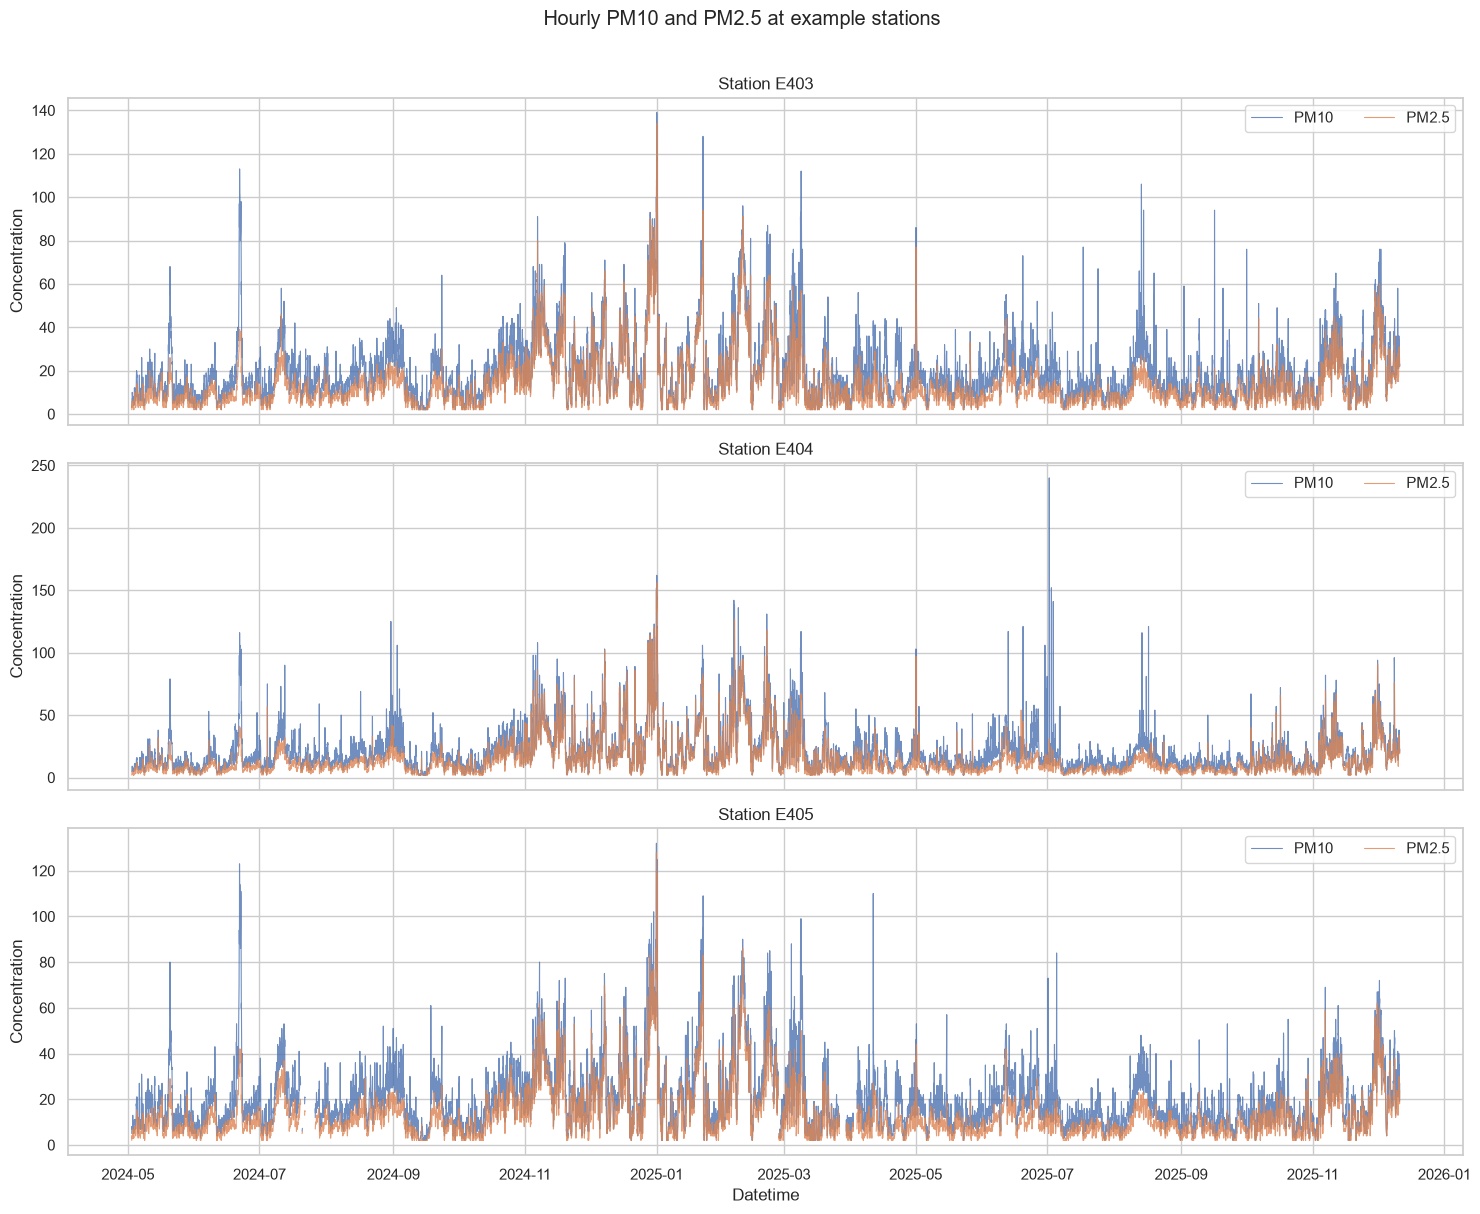

Takeaway: the time series show temporal variability and remaining gaps for the selected stations: E403, E404, E405.


In [10]:
example_stations = sorted(df_clean["station"].dropna().unique())[:3]
fig, axes = plt.subplots(len(example_stations), 1, figsize=(15, 4 * max(1, len(example_stations))), sharex=True)
axes = np.atleast_1d(axes)
for ax, station_id in zip(axes, example_stations):
    subset = df_clean.loc[df_clean["station"].eq(station_id)]
    ax.plot(subset["datetime"], subset["PM10"], label="PM10", linewidth=0.8, alpha=0.8)
    ax.plot(subset["datetime"], subset["PM2.5"], label="PM2.5", linewidth=0.8, alpha=0.8)
    ax.set_title(f"Station {station_id}")
    ax.set_ylabel("Concentration")
    ax.legend(ncol=2)
axes[-1].set_xlabel("Datetime")
fig.suptitle("Hourly PM10 and PM2.5 at example stations", y=1.01)
fig.tight_layout()
plt.show()
print(f"Takeaway: the time series show temporal variability and remaining gaps for the selected stations: {', '.join(example_stations)}.")

## 9. Pollutant distributions (linear/log histograms and station boxplots)

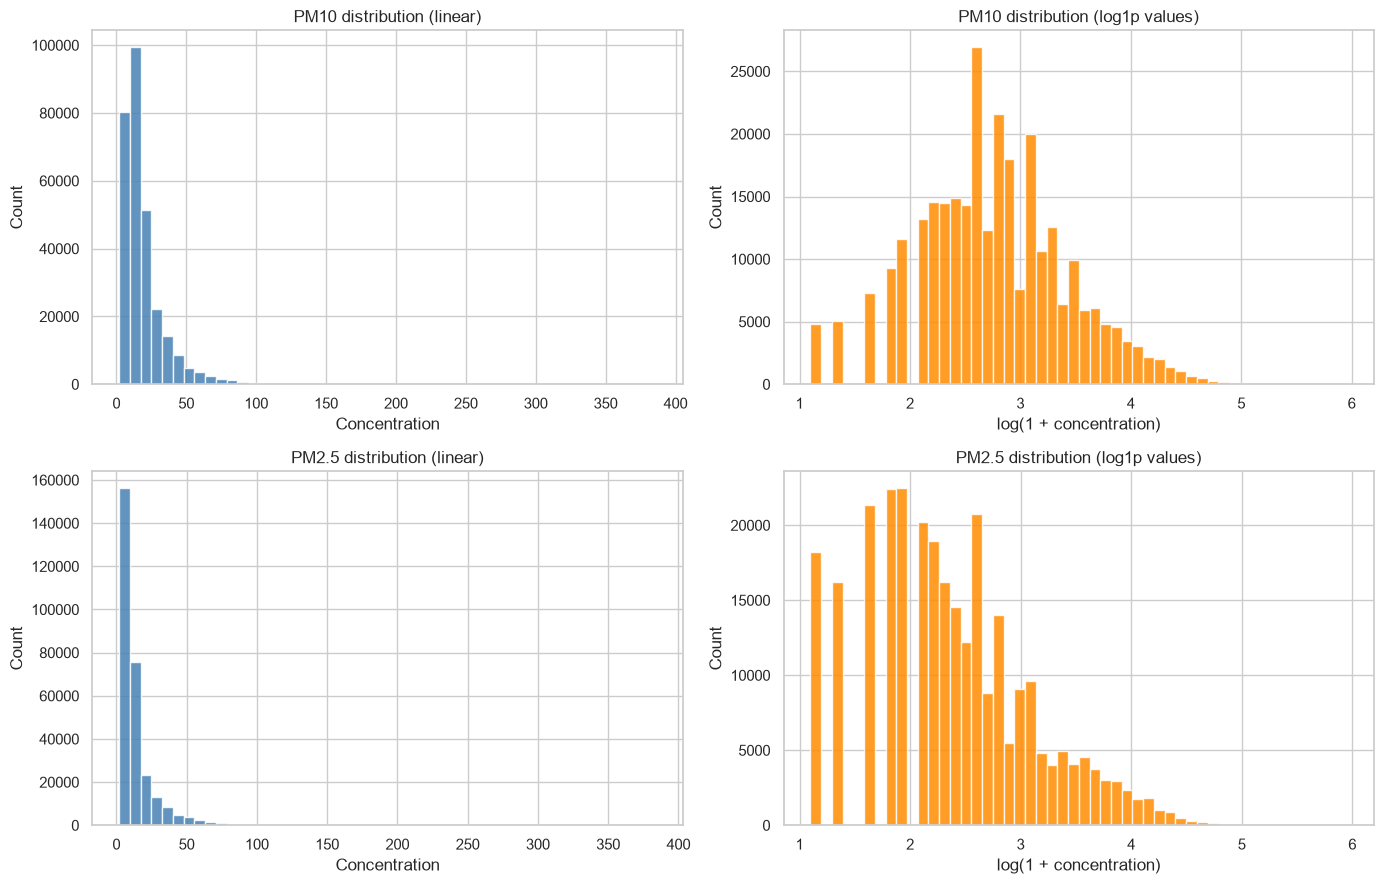

Takeaway: compare the linear and log1p views to assess skew and whether extreme pollution episodes dominate the distributions.


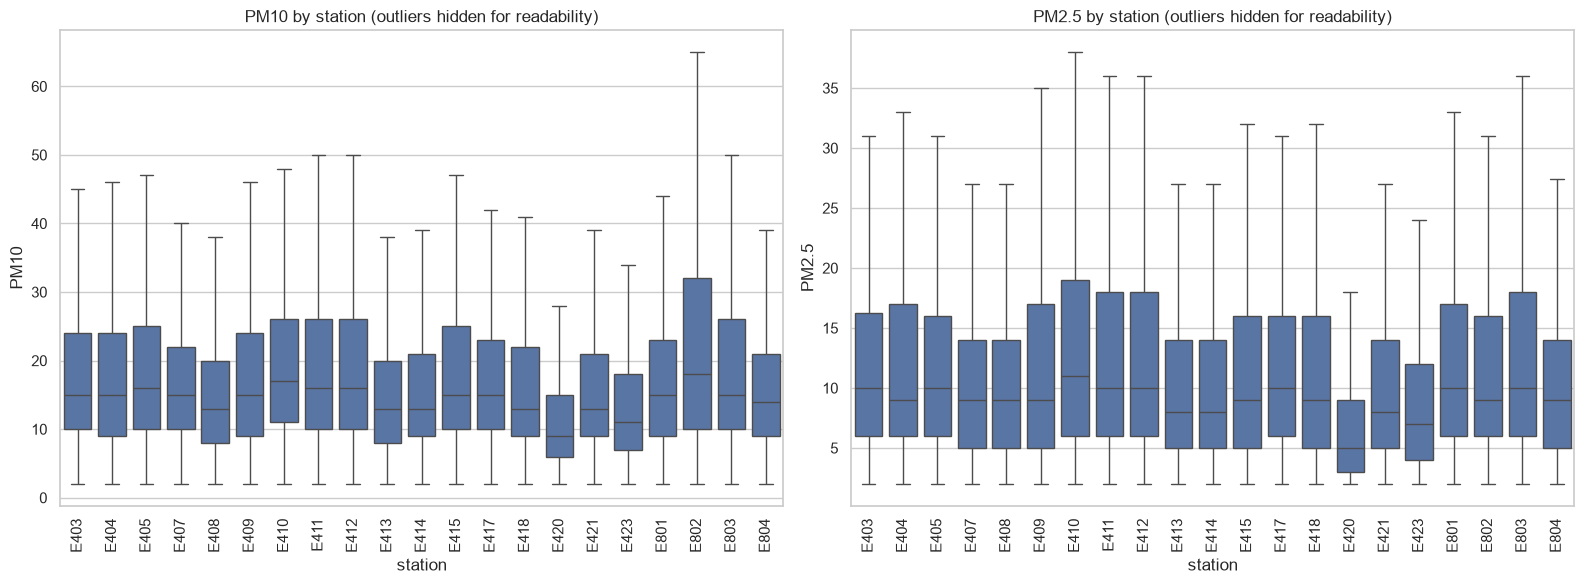

Takeaway: station boxplots reveal differences in typical levels and spread; hidden fliers remain in the data and summary statistics.


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, pollutant in enumerate(["PM10", "PM2.5"]):
    values = df_clean[pollutant].dropna()
    axes[row, 0].hist(values, bins=50, color="steelblue", alpha=0.85)
    axes[row, 0].set(title=f"{pollutant} distribution (linear)", xlabel="Concentration", ylabel="Count")
    axes[row, 1].hist(np.log1p(values), bins=50, color="darkorange", alpha=0.85)
    axes[row, 1].set(title=f"{pollutant} distribution (log1p values)", xlabel="log(1 + concentration)", ylabel="Count")
fig.tight_layout()
plt.show()
print("Takeaway: compare the linear and log1p views to assess skew and whether extreme pollution episodes dominate the distributions.")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, pollutant in zip(axes, ["PM10", "PM2.5"]):
    sns.boxplot(data=df_clean, x="station", y=pollutant, ax=ax, showfliers=False)
    ax.set_title(f"{pollutant} by station (outliers hidden for readability)")
    ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
plt.show()
print("Takeaway: station boxplots reveal differences in typical levels and spread; hidden fliers remain in the data and summary statistics.")

## 10. Average pollution by hour, weekday, and month

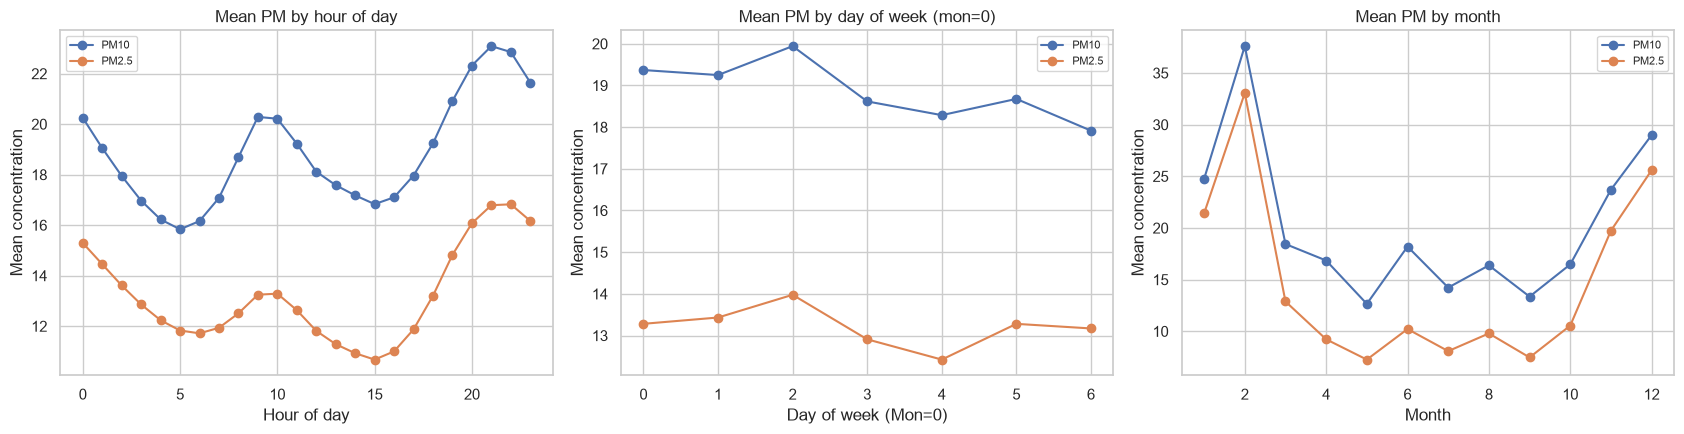

Takeaway (Hour of day, PM10): highest group mean occurs at 21.
Takeaway (Hour of day, PM2.5): highest group mean occurs at 22.
Takeaway (Day of week (Mon=0), PM10): highest group mean occurs at 2.
Takeaway (Day of week (Mon=0), PM2.5): highest group mean occurs at 2.
Takeaway (Month, PM10): highest group mean occurs at 2.
Takeaway (Month, PM2.5): highest group mean occurs at 2.


In [12]:
seasonal_groups = [("hour", "Hour of day"), ("day_of_week", "Day of week (Mon=0)"), ("month", "Month")]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (group_column, label) in zip(axes, seasonal_groups):
    seasonal = df_clean.groupby(group_column)[["PM10", "PM2.5"]].mean()
    seasonal.plot(ax=ax, marker="o")
    ax.set(title=f"Mean PM by {label.lower()}", xlabel=label, ylabel="Mean concentration")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for group_column, label in seasonal_groups:
    means = df_clean.groupby(group_column)[["PM10", "PM2.5"]].mean()
    for pollutant in ["PM10", "PM2.5"]:
        peak = means[pollutant].idxmax()
        print(f"Takeaway ({label}, {pollutant}): highest group mean occurs at {peak}.")

## 11. PM2.5 / PM10 ratio over time and by station

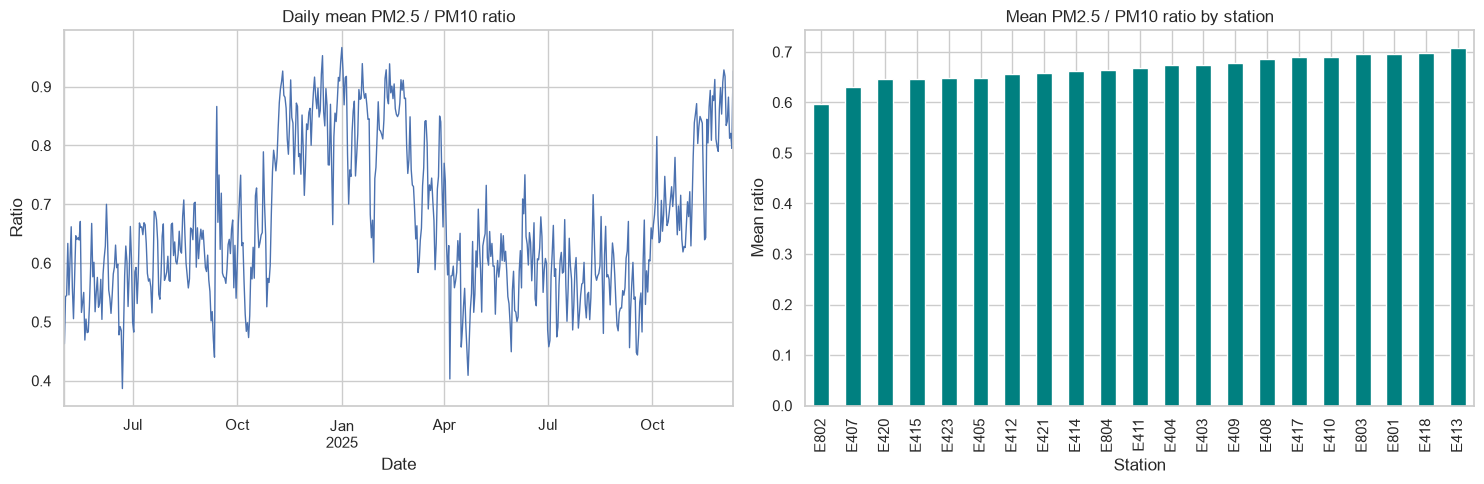

Takeaway: station-average ratios range from 0.597 to 0.707; ratios are undefined when PM10 is zero or either pollutant is missing.


In [13]:
ratio_valid = df_clean["PM10"].gt(0) & df_clean["PM2.5"].notna()
df_clean["PM2.5_PM10_ratio"] = (df_clean["PM2.5"] / df_clean["PM10"]).where(ratio_valid)
ratio_daily = df_clean.groupby(pd.Grouper(key="datetime", freq="D"))["PM2.5_PM10_ratio"].mean()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ratio_daily.plot(ax=axes[0], linewidth=1)
axes[0].set(title="Daily mean PM2.5 / PM10 ratio", xlabel="Date", ylabel="Ratio")
station_ratio = df_clean.groupby("station")["PM2.5_PM10_ratio"].mean().sort_values()
station_ratio.plot(kind="bar", ax=axes[1], color="teal")
axes[1].set(title="Mean PM2.5 / PM10 ratio by station", xlabel="Station", ylabel="Mean ratio")
axes[1].tick_params(axis="x", rotation=90)
fig.tight_layout()
plt.show()
print(f"Takeaway: station-average ratios range from {station_ratio.min():.3f} to {station_ratio.max():.3f}; ratios are undefined when PM10 is zero or either pollutant is missing.")

## 12. Pollutant/weather correlations and PM2.5 vs PM10 scatter

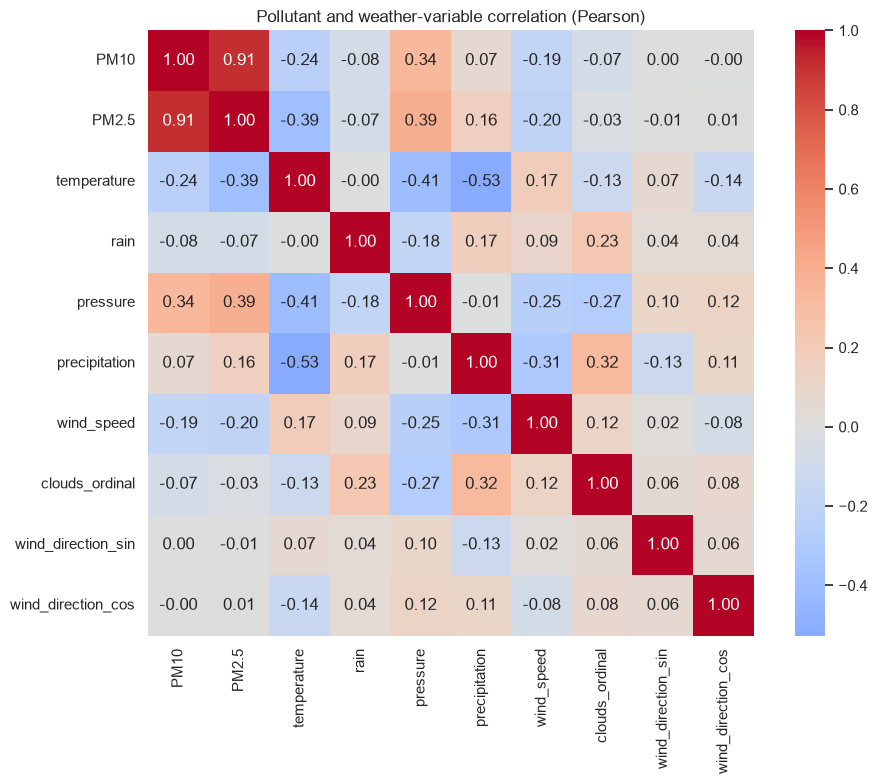

Takeaway: pairwise-complete Pearson correlation between PM2.5 and PM10 is 0.911; correlation is descriptive, not causal.


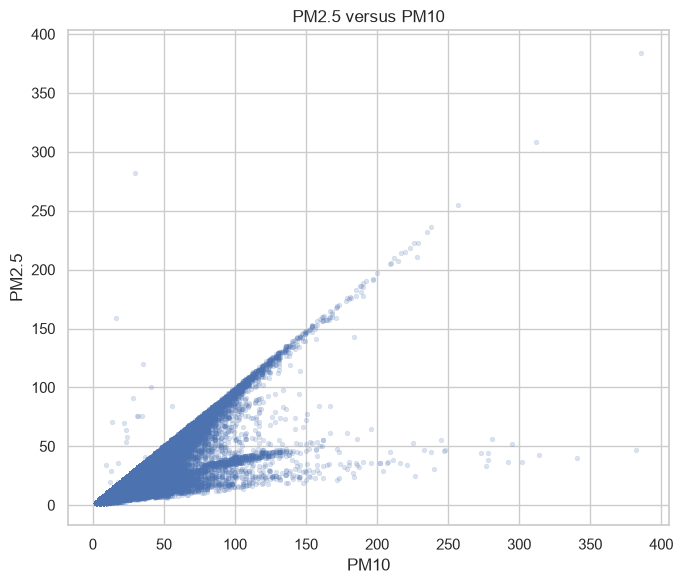

Takeaway: the scatter uses 291,956 paired observations; inspect the cloud for nonlinearity, changing variance, or influential episodes.


In [14]:
weather_candidates = ["temperature", "rain", "pressure", "precipitation", "wind_speed", "clouds_ordinal", "wind_direction_sin", "wind_direction_cos"]
correlation_columns = [column for column in ["PM10", "PM2.5", *weather_candidates] if column in df_clean.columns]
pollution_weather_corr = df_clean[correlation_columns].corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(pollution_weather_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Pollutant and weather-variable correlation (Pearson)")
plt.tight_layout()
plt.show()
pm_corr = pollution_weather_corr.loc["PM2.5", "PM10"] if {"PM2.5", "PM10"}.issubset(pollution_weather_corr.index) else np.nan
print(f"Takeaway: pairwise-complete Pearson correlation between PM2.5 and PM10 is {pm_corr:.3f}; correlation is descriptive, not causal.")

scatter_data = df_clean[["PM10", "PM2.5"]].dropna()
plt.figure(figsize=(7, 6))
sns.scatterplot(data=scatter_data, x="PM10", y="PM2.5", alpha=0.2, s=12, edgecolor=None)
plt.title("PM2.5 versus PM10")
plt.tight_layout()
plt.show()
print(f"Takeaway: the scatter uses {len(scatter_data):,} paired observations; inspect the cloud for nonlinearity, changing variance, or influential episodes.")

## 13. Lagged cross-correlation (−24 to +24 hours)

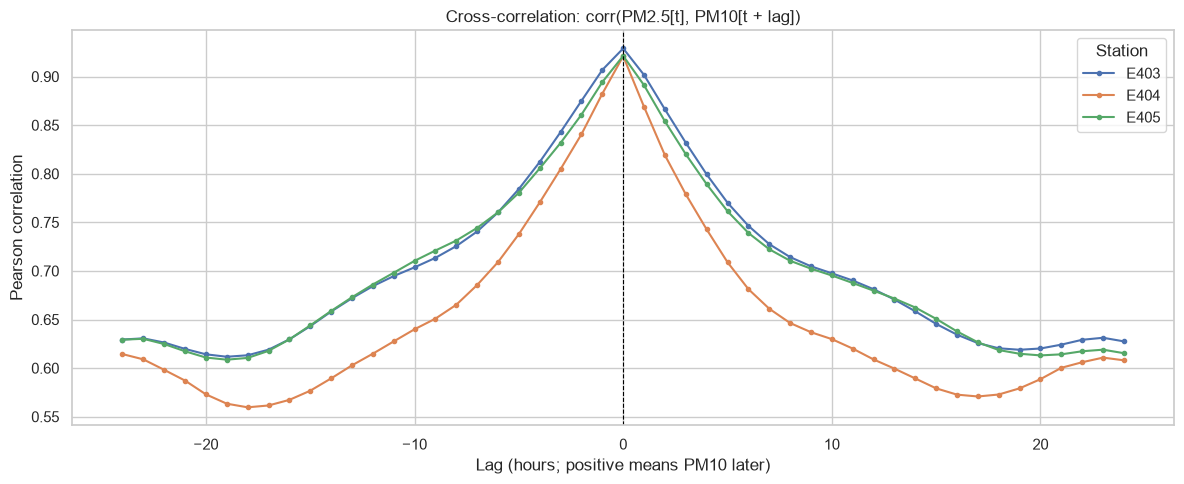

Takeaway: the lag with the strongest association is descriptive and may reflect shared emissions, persistence, or missingness rather than predictive causality.


In [15]:
lag_stations = sorted(df_clean["station"].dropna().unique())[:3]
lags = range(-24, 25)
fig, ax = plt.subplots(figsize=(12, 5))
for station_id in lag_stations:
    subset = df_clean.loc[df_clean["station"].eq(station_id), ["datetime", "PM2.5", "PM10"]].drop_duplicates("datetime").set_index("datetime").sort_index()
    hourly = subset[["PM2.5", "PM10"]].asfreq("h")
    correlations = [hourly["PM2.5"].corr(hourly["PM10"].shift(-lag)) for lag in lags]
    ax.plot(list(lags), correlations, marker=".", label=station_id)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set(title="Cross-correlation: corr(PM2.5[t], PM10[t + lag])", xlabel="Lag (hours; positive means PM10 later)", ylabel="Pearson correlation")
ax.legend(title="Station")
plt.tight_layout()
plt.show()
print("Takeaway: the lag with the strongest association is descriptive and may reflect shared emissions, persistence, or missingness rather than predictive causality.")

## 14. Station comparison: mean levels, missingness, and cross-station correlation

,PM10,PM2.5,PM10_missing_pct,PM2.5_missing_pct
station,,,,
E420,12.304592,7.396087,0.312057,0.283688
E423,14.872671,9.997355,1.141844,1.141844
E408,16.449220,11.775842,1.269504,1.269504
E414,17.220733,11.796669,0.602837,0.588652
E421,17.233637,11.898719,0.283688,0.283688
E407,18.369432,12.040699,2.886525,2.886525
E804,17.850266,12.203079,3.304965,3.212766
E413,16.604044,12.511712,0.397163,0.397163
E405,19.355271,13.056591,2.609929,2.609929


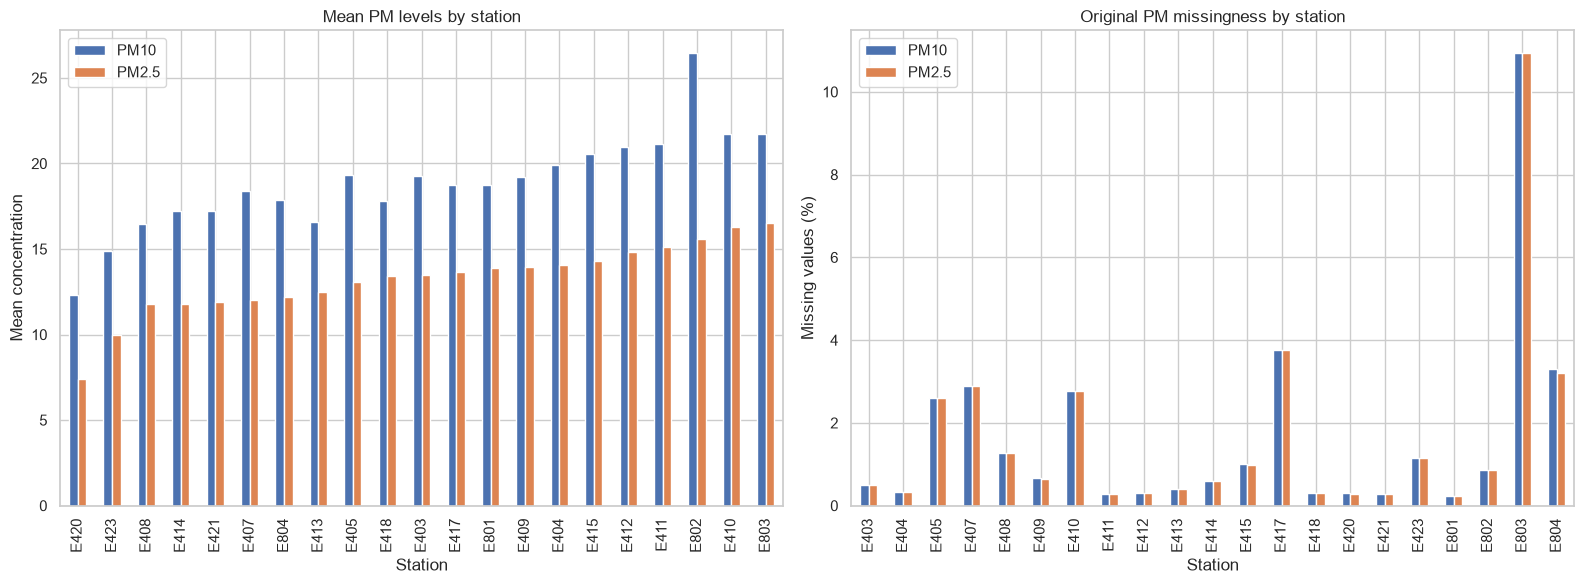

Takeaway: station mean PM2.5 ranges from 7.40 to 16.52; missingness should be considered when comparing stations.


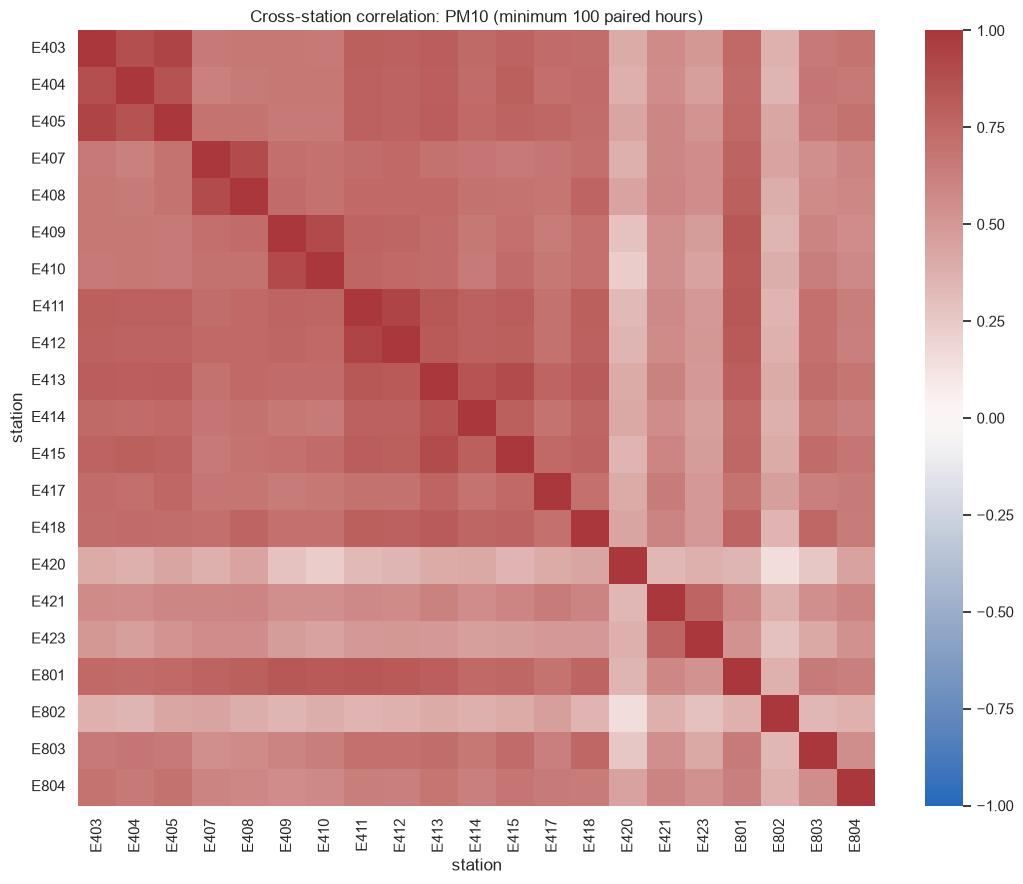

Takeaway (PM10): cross-station correlations range from 0.156 to 0.935 among available pairs.


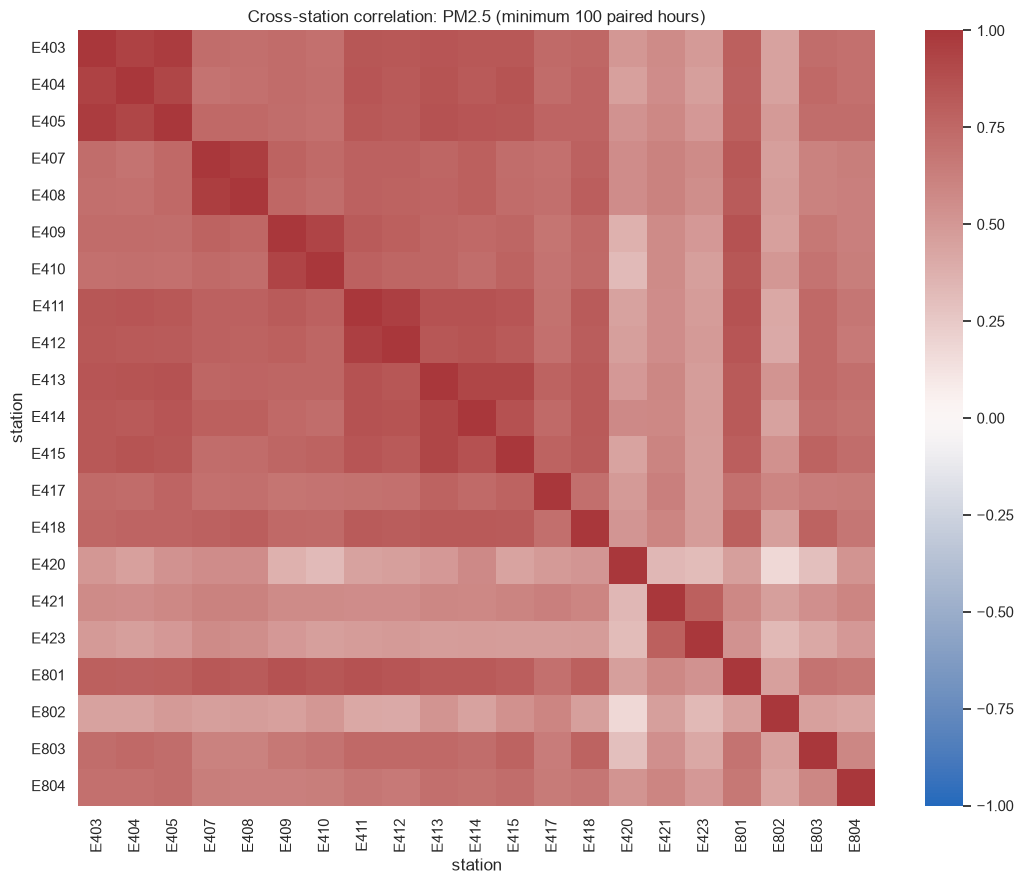

Takeaway (PM2.5): cross-station correlations range from 0.176 to 0.970 among available pairs.


In [16]:
station_means = df_clean.groupby("station")[["PM10", "PM2.5"]].mean().sort_values("PM2.5")
station_missing = df.set_index("station")[["PM10", "PM2.5"]].isna().groupby(level="station").mean() * 100
station_comparison = station_means.join(station_missing.add_suffix("_missing_pct"))
display(station_comparison)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
station_means.plot(kind="bar", ax=axes[0])
axes[0].set(title="Mean PM levels by station", ylabel="Mean concentration", xlabel="Station")
axes[0].tick_params(axis="x", rotation=90)
station_missing.plot(kind="bar", ax=axes[1])
axes[1].set(title="Original PM missingness by station", ylabel="Missing values (%)", xlabel="Station")
axes[1].tick_params(axis="x", rotation=90)
fig.tight_layout()
plt.show()
print(f"Takeaway: station mean PM2.5 ranges from {station_means['PM2.5'].min():.2f} to {station_means['PM2.5'].max():.2f}; missingness should be considered when comparing stations.")

for pollutant in ["PM10", "PM2.5"]:
    station_wide = df_clean.pivot_table(index="datetime", columns="station", values=pollutant)
    station_corr = station_wide.corr(min_periods=100)
    plt.figure(figsize=(11, 9))
    sns.heatmap(station_corr, cmap="vlag", center=0, vmin=-1, vmax=1)
    plt.title(f"Cross-station correlation: {pollutant} (minimum 100 paired hours)")
    plt.tight_layout()
    plt.show()
    valid_pairs = station_corr.where(~np.eye(len(station_corr), dtype=bool)).stack().dropna()
    if not valid_pairs.empty:
        print(f"Takeaway ({pollutant}): cross-station correlations range from {valid_pairs.min():.3f} to {valid_pairs.max():.3f} among available pairs.")
    else:
        print(f"Takeaway ({pollutant}): insufficient overlapping observations for cross-station correlations.")

## 15. ACF and PACF for one station (computed directly with NumPy)

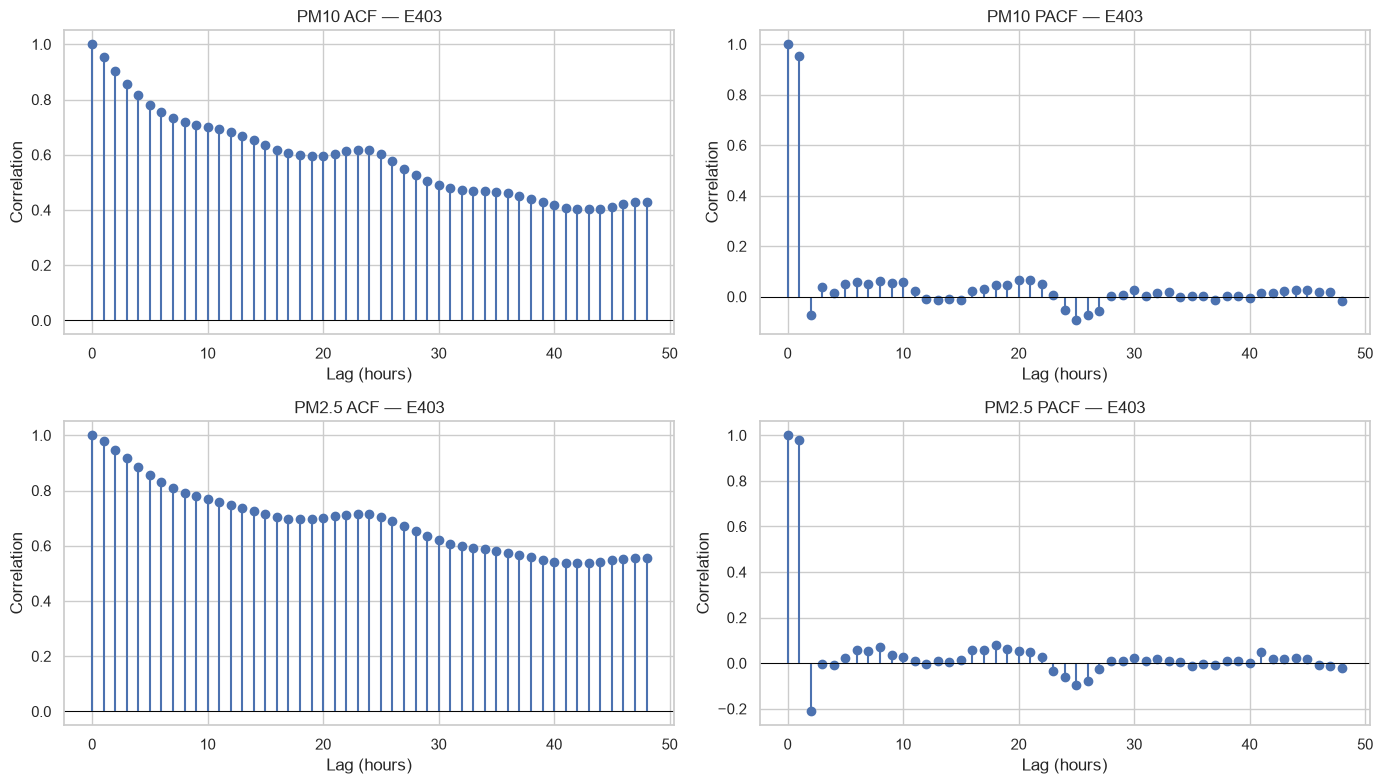

Takeaway: persistent short-lag autocorrelation is common in hourly pollution series; use chronological validation to avoid leakage.


In [17]:
acf_station = sorted(df_clean["station"].dropna().unique())[0]
max_lag = 48
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, pollutant in enumerate(["PM10", "PM2.5"]):
    series = df_clean.loc[df_clean["station"].eq(acf_station)].drop_duplicates("datetime").set_index("datetime")[pollutant].sort_index().asfreq("h")
    series = series.interpolate(limit=3, limit_area="inside").to_numpy(dtype=float)
    if np.isfinite(series).sum() <= max_lag + 1:
        print(f"Skipping {pollutant}: not enough non-missing values for {max_lag} lags.")
        continue
    acf_values = [1.0]
    for lag in range(1, max_lag + 1):
        current, previous = series[lag:], series[:-lag]
        valid = np.isfinite(current) & np.isfinite(previous)
        if valid.sum() < 3:
            acf_values.append(np.nan)
        else:
            acf_values.append(np.corrcoef(current[valid], previous[valid])[0, 1])
    pacf_values = [1.0]
    for lag in range(1, max_lag + 1):
        target = series[lag:]
        predictors = np.column_stack([series[lag - offset - 1:len(series) - offset - 1] for offset in range(lag)])
        valid = np.isfinite(target) & np.isfinite(predictors).all(axis=1)
        if valid.sum() <= lag + 1:
            pacf_values.append(np.nan)
            continue
        target = target[valid]
        predictors = predictors[valid]
        nuisance = np.column_stack([np.ones(len(target)), predictors[:, :-1]])
        target_residual = target - nuisance @ np.linalg.lstsq(nuisance, target, rcond=None)[0]
        lag_residual = predictors[:, -1] - nuisance @ np.linalg.lstsq(nuisance, predictors[:, -1], rcond=None)[0]
        pacf_values.append(np.corrcoef(target_residual, lag_residual)[0, 1])
    for ax, values, title in [(axes[row, 0], acf_values, "ACF"), (axes[row, 1], np.asarray(pacf_values), "PACF")]:
        ax.stem(range(max_lag + 1), values, basefmt=" ")
        ax.axhline(0, color="black", linewidth=0.7)
        ax.set(title=f"{pollutant} {title} — {acf_station}", xlabel="Lag (hours)", ylabel="Correlation")
fig.tight_layout()
plt.show()
print("Takeaway: persistent short-lag autocorrelation is common in hourly pollution series; use chronological validation to avoid leakage.")

## 16. Data-quality findings and modeling readiness

In [18]:
print("DATA QUALITY SUMMARY")
print(f"Stations: {df_clean['station'].nunique()} (expected {EXPECTED_STATIONS}); rows: {len(df_clean):,} (expected {EXPECTED_STATIONS * EXPECTED_ROWS_PER_STATION:,}).")
print(f"Stations with timestamp gaps: {int(gap_report['missing_hours'].fillna(0).gt(0).sum())}.")
print(f"Duplicate station/timestamp rows: {int(duplicate_rows.sum())}.")
print(f"Invalid values set to missing: {sum(invalid_counts.values()):,} across checked numeric fields.")
print(f"PM10 short-gap interpolation count: {int(df_clean.get('PM10_interpolated', pd.Series(dtype='int8')).sum()):,}.")
print(f"PM2.5 short-gap interpolation count: {int(df_clean.get('PM2.5_interpolated', pd.Series(dtype='int8')).sum()):,}.")
print("Review the missingness heatmap, gap report, range-check counts, and station comparison before modeling. Preserve the interpolation flags and fit any future imputers on training data only.")

DATA QUALITY SUMMARY
Stations: 21 (expected 21); rows: 296,100 (expected 296,100).
Stations with timestamp gaps: 0.
Duplicate station/timestamp rows: 0.
Invalid values set to missing: 0 across checked numeric fields.
PM10 short-gap interpolation count: 758.
PM2.5 short-gap interpolation count: 735.
Review the missingness heatmap, gap report, range-check counts, and station comparison before modeling. Preserve the interpolation flags and fit any future imputers on training data only.


### Key findings and limitations

The supplied data contain 21 stations and 296,100 rows, matching the expected totals and date range. The initial QA found no duplicate station/timestamp keys or hourly gaps, and no values outside the configured physical ranges. Wind direction is missing for 49.17% of observations. Short-gap interpolation filled 758 PM10 and 735 PM2.5 values; longer gaps remain missing. Overall PM2.5–PM10 correlation is 0.911, while mean station PM2.5 ranges from 7.40 to 16.52 and station-average PM2.5/PM10 ratios range from 0.597 to 0.707. Hourly means peak in the evening and monthly means peak in February for both pollutants. These are descriptive findings; station-specific missingness and strong temporal persistence must be accounted for in chronological validation. Interpolated values are explicitly flagged.

### Next steps
- Create chronological train/validation/test splits before fitting any learned preprocessing.
- Define forecast horizons and construct leakage-safe input/output windows per station (or a documented multi-station strategy).
- Establish persistence and seasonal-naive baselines, then compare later LSTM, TCN, 1D-CNN, and the planned newer architectures.
- Fit scalers and any additional imputers on training data only; evaluate with metrics appropriate to both pollutants and inspect station-level errors.